# Segmenting guidewires and microcatheters in fluoroscopy
**Denos Kume and Oluwole Shokunbi · Computer vision and image processing · Centrale Nantes**

## Retrospective imaging research review
This case review evaluates instrument visibility in an exported teaching sequence. The review unit is one acquisition with ten frames. It is intended for offline engineering and reader assessment. Clinical validation, patient outcomes and real-time guidance are outside the available evidence.

## Mission
Identify moving instruments in a noisy fluoroscopic sequence and show where the predicted tool overlaps the manual tracing. The project follows the Background Subtraction practical by Diana Mateus at Centrale Nantes.

## Results at a glance
The classical motion pipeline is retained as a baseline. The final method estimates an instrument likelihood from intensity, dark ridges and temporal change, then follows one continuous path from the lower edge. All ten frames receive predictions, including the background reference used in the classical experiments.

This is a retrospective, within-acquisition experiment. The new supervised method fits on other manually traced frames from the same acquisition. Each test pair and its immediate neighbors are excluded from fitting. The temporal background uses the raw images of the whole sequence. Model and path settings were explored on this sequence; the scores are development results, not independent patient-level validation.

Mean Dice across all ten held-out predictions: **0.882**. Nine-frame mean excluding the classical background reference: **0.876**.

**Run the project.** Keep `catheter.zip` beside the notebook, install `requirements.txt` in a Python 3.12 environment, then restart the kernel and run all cells. The first section tests individual processing steps. The second applies the retained pipeline to the sequence and evaluates every mask.

In [1]:
from io import BytesIO
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import struct
import zlib
from scipy import ndimage
from sklearn.mixture import GaussianMixture

DATA_ARCHIVE = Path("catheter.zip")
with ZipFile(DATA_ARCHIVE) as archive:
    FRAME_NUMBERS = tuple(sorted(
        int(Path(path).stem.removeprefix("frame_"))
        for path in archive.namelist() if Path(path).match("catheter/frame_*.png")
    ))
FIXED_THRESHOLD = 0.10
GAUSSIAN_SIGMA = 1.0
RADIUS_PIXELS = 2
RANDOM_SEED = 42

# Use a circular neighborhood so the radius has the same meaning along both image axes.
offsets = np.arange(-RADIUS_PIXELS, RADIUS_PIXELS + 1)
disk_footprint = offsets[:, None] ** 2 + offsets[None, :] ** 2 <= RADIUS_PIXELS ** 2

### Data and evaluation protocol
The two manual tracings are merged and the tool foreground is dilated with a radius-two disk. The classical pipeline uses manual masks for evaluation. The supervised extension also uses annotations from the training frames in each fold.

In [2]:
def read_grayscale_image(archive, filename):
    image_format = Path(filename).suffix[1:]
    image = plt.imread(BytesIO(archive.read(f"catheter/{filename}")), format=image_format)
    # The TIFF annotations may be returned as RGBA; the first channel contains the tracing.
    grayscale = image[..., 0] if image.ndim == 3 else image
    if np.issubdtype(grayscale.dtype, np.floating):
        return np.rint(255 * grayscale).astype(np.uint8)
    return grayscale

def load_fluoroscopy_sequence(archive_path, frame_numbers):
    frames, reference_masks = [], []
    with ZipFile(archive_path) as archive:
        for frame_number in frame_numbers:
            frame = read_grayscale_image(archive, f"frame_{frame_number}.png")
            guidewire = read_grayscale_image(archive, f"{frame_number}_GuideWire.tiff")
            microcatheter = read_grayscale_image(archive, f"{frame_number}_MicroCath.tiff")
            if guidewire.shape != frame.shape or microcatheter.shape != frame.shape:
                raise ValueError(f"Image and annotation dimensions differ for frame {frame_number}.")
            # Dark pixels in either tracing count as foreground; the task treats both instruments as one class.
            instrument_mask = (guidewire < 128) | (microcatheter < 128)
            # Allow a two-pixel tolerance around the manual tracing when scoring predictions.
            reference_masks.append(ndimage.binary_dilation(instrument_mask, structure=disk_footprint))
            frames.append(frame.astype(float) / 255)
    return np.stack(frames), np.stack(reference_masks)


frames, reference_masks = load_fluoroscopy_sequence(DATA_ARCHIVE, FRAME_NUMBERS)
print(f"Loaded {len(frames)} frames of {frames.shape[1]} × {frames.shape[2]} pixels.")
print(f"Background reference: {FRAME_NUMBERS[0]} | Subsequent frames: {len(frames) - 1}")

Loaded 10 frames of 512 × 512 pixels.
Background reference: 201 | Subsequent frames: 9


### Prepare the grayscale images for review
Apply a common brightness window to the entire acquisition so that the display remains consistent as the instrument moves. A mild local contrast boost preserves the dark line against the surrounding anatomy; a gamma curve lifts the darker midtones. Keep the original intensities for the segmentation experiments and use the enhanced images for the review panels and overlays.

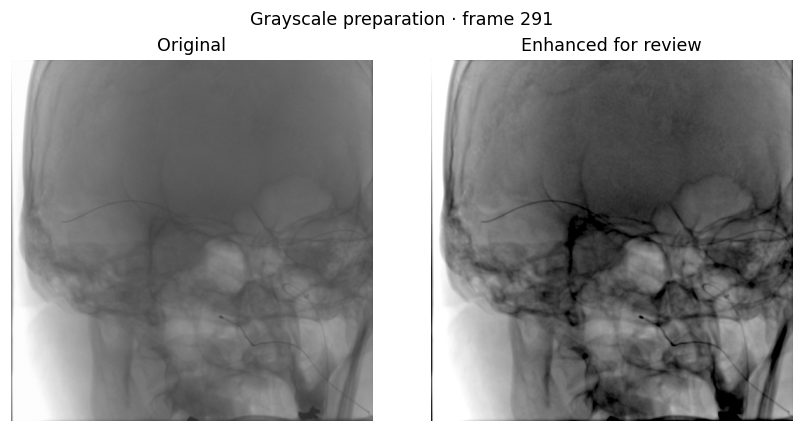

In [3]:
display_window = np.percentile(frames, [0.5, 99.5])

def prepare_review_image(frame, window):
    lower, upper = window
    if upper <= lower:
        return frame.copy()
    # Boost local detail after light smoothing to limit amplification of pixel noise.
    smoothed = ndimage.gaussian_filter(frame, sigma=0.65)
    local_background = ndimage.gaussian_filter(smoothed, sigma=10)
    detailed = smoothed + 0.7 * (smoothed - local_background)
    windowed = np.clip((detailed - lower) / (upper - lower), 0, 1)
    return windowed ** 0.60


display_frames = np.stack([prepare_review_image(frame, display_window) for frame in frames])
figure, axes = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)
for axis, image, title in zip(axes, [frames[-1], display_frames[-1]], ["Original", "Enhanced for review"]):
    axis.imshow(image, cmap="gray", vmin=0, vmax=1)
    axis.set_title(title)
    axis.set_axis_off()
figure.suptitle(f"Grayscale preparation · frame {FRAME_NUMBERS[-1]}")
plt.show()

### Acquisition intake and technical quality control
Verify the source archive and annotation pairs before comparing methods. The dataset contains PNG images and TIFF tracings. Acquisition timing, pixel spacing, projection geometry and reader credentials are undocumented. Measurements therefore use pixels and frame order. The reviewer assesses alignment and instrument visibility visually.

In [4]:
import hashlib
import csv
import json

with ZipFile(DATA_ARCHIVE) as archive:
    members = archive.namelist()
    if len(set(members)) != len(members):
        raise ValueError("Duplicate filenames in the acquisition archive.")
    for number in FRAME_NUMBERS:
        for filename in [f"frame_{number}.png", f"{number}_GuideWire.tiff", f"{number}_MicroCath.tiff"]:
            if f"catheter/{filename}" not in members:
                raise ValueError(f"Missing input for frame {number}: {filename}")
if len(FRAME_NUMBERS) < 2 or not np.isfinite(frames).all():
    raise ValueError("A valid reference and at least one subsequent frame are required.")
archive_digest = hashlib.sha256(DATA_ARCHIVE.read_bytes()).hexdigest()
print(f"Paired inputs verified for {len(frames)} frames. Source SHA-256: {archive_digest}")

Paired inputs verified for 10 frames. Source SHA-256: c291eea30db60c96b8d6cea49ea0d1ff2630ca13be302cc134f8238ec865742e


### Define the evaluation metrics
On 0/1 masks, SAD is the **sum** of absolute differences, or the number of misclassified pixels. MAE is the corresponding mean. MSE follows the assignment’s NumPy hint and uses the mean squared difference. Its value equals MAE for binary masks. PSNR uses a peak value of 1. SNR uses the mean squared manual mask as its reference power. SSE is also reported because the brief mentions the sum of squared differences as well as MSE. Dice and IoU measure overlap of the instruments, which occupy only a small fraction of the frame.

In [5]:
def measure_mask_errors(output_mask, manual_mask):
    # Cast before subtracting so negative differences do not wrap in unsigned arithmetic.
    difference = output_mask.astype(float) - manual_mask.astype(float)
    absolute_error = np.abs(difference)
    mse = np.mean(difference**2)
    signal_power = np.mean(manual_mask.astype(float)**2)
    predicted_tool, annotated_tool = output_mask == 0, manual_mask == 0
    intersection = np.count_nonzero(predicted_tool & annotated_tool)
    union = np.count_nonzero(predicted_tool | annotated_tool)
    combined_count = predicted_tool.sum() + annotated_tool.sum()
    return {
        "SAD": int(absolute_error.sum()), "MAE": absolute_error.mean(), "SSE": np.sum(difference**2), "MSE": mse,
        "PSNR (dB)": -10 * np.log10(mse) if mse else np.inf,
        "SNR (dB)": 10 * np.log10(signal_power / mse) if mse else np.inf,
        "Dice": 2 * intersection / combined_count if combined_count else 1.0,
        "IoU": intersection / union if union else 1.0,
    }

## 1. Intermediate steps — code and description
The reference and nine later frames are processed with the same settings within each experiment. Compare the nine later frames here, then report the entire sequence in section 2. Each trial displays the full sequence in chronological order, with the same error colors throughout. Green indicates correct instrument pixels, orange indicates false positives and blue indicates missed tools.

In [6]:
manual_masks = (~reference_masks).astype(np.uint8)
trial_scores = {}


def report_trial(label, predictions):
    measurements = [measure_mask_errors(prediction, target)
                    for prediction, target in zip(predictions[1:], manual_masks[1:], strict=True)]
    averages = {key: np.mean([row[key] for row in measurements]) for key in measurements[0]}
    trial_scores[label] = averages
    print(label + " | nine-frame means")
    print("   ".join(f"{key}: {averages[key]:.3f}" for key in
                     ["SAD", "MSE", "PSNR (dB)", "SNR (dB)", "Dice", "IoU"]))
    # Keep the reference visible in the gallery even though it has no relative motion.
    columns = min(5, len(predictions))
    rows = (len(predictions) + columns - 1) // columns
    figure, axes = plt.subplots(rows, columns, figsize=(2.3 * columns, 2.4 * rows),
                                squeeze=False, constrained_layout=True)
    for axis in axes.flat:
        axis.set_axis_off()
    for axis, frame, number, prediction, target in zip(
        axes.flat, display_frames, FRAME_NUMBERS, predictions, reference_masks
    ):
        tool = prediction == 0
        overlay = np.repeat(frame[:, :, None], 3, axis=2)
        overlay[tool & target] = [0.3, 1, 0.3]
        overlay[tool & ~target] = [1, 0.55, 0.1]
        overlay[~tool & target] = [0.1, 0.75, 1]
        axis.imshow(overlay)
        axis.set_title(f"Frame {number}", fontsize=10)
    figure.suptitle(f"{label} · error overlays for all {len(predictions)} frames")
    plt.show()


def threshold_masks(motion_maps):
    return [(motion_map <= FIXED_THRESHOLD).astype(np.uint8) for motion_map in motion_maps]

### 1.1 Baseline — signed difference
A tool that moves into a pixel darkens it. Subtract each frame from the first and threshold positive changes at 0.10 on the normalized intensity scale.

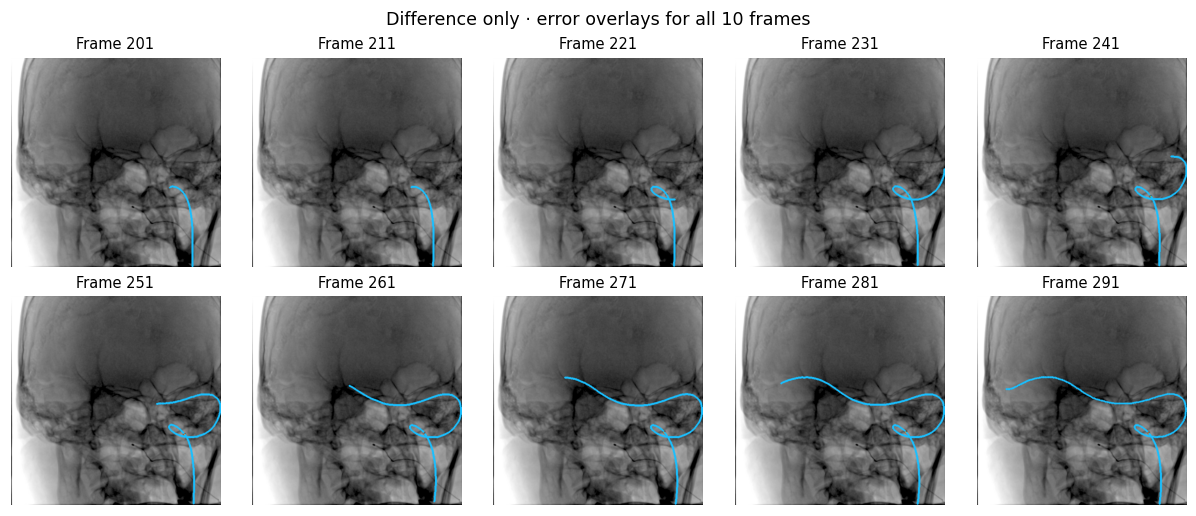

Difference only | nine-frame means
SAD: 2645.889   MSE: 0.010   PSNR (dB): 20.350   SNR (dB): 20.306   Dice: 0.001   IoU: 0.000


In [7]:
raw_differences = [frames[0] - frame for frame in frames]
report_trial("Difference only", threshold_masks(raw_differences))

### 1.2 Histogram transformation
The baseline misses almost all tool pixels. Stretch each image between its minimum and 90th percentile to reduce the influence of bright anatomy. Stretch the difference between its 10th percentile and maximum before applying the same threshold.

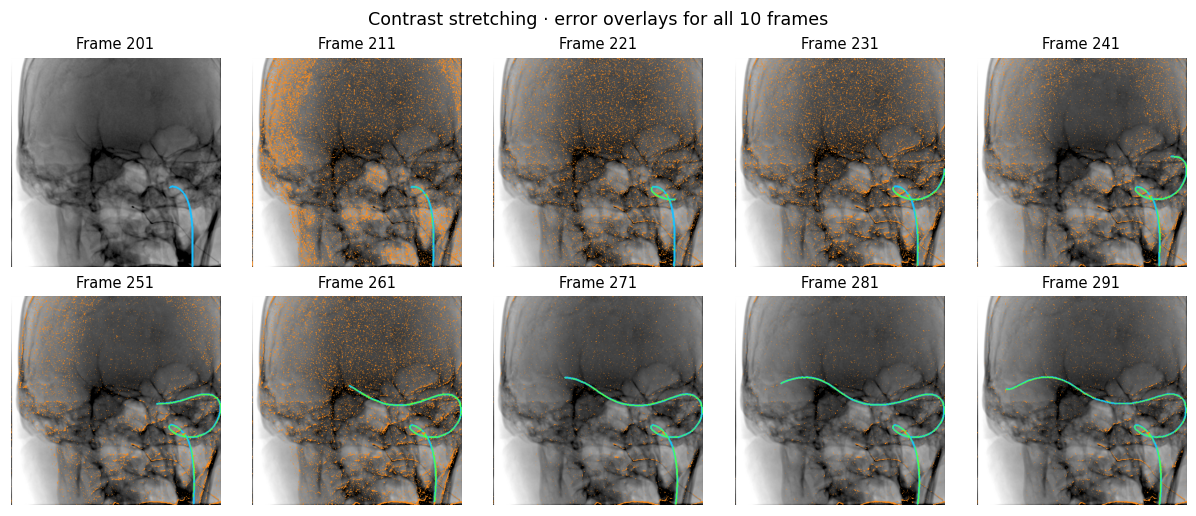

Contrast stretching | nine-frame means
SAD: 16541.333   MSE: 0.063   PSNR (dB): 12.793   SNR (dB): 12.749   Dice: 0.199   IoU: 0.119


In [8]:
def stretch_contrast(image, lower_percentile, upper_percentile):
    lower_bound, upper_bound = np.percentile(image, [lower_percentile, upper_percentile])
    # A constant intensity range contains no contrast to enhance.
    if upper_bound == lower_bound:
        return np.zeros_like(image)
    # Clip values outside the percentile bounds so rare extremes do not set the contrast scale.
    return np.clip((image - lower_bound) / (upper_bound - lower_bound), 0, 1)




def compute_normalized_differences(prepared_frames):
    return [stretch_contrast(prepared_frames[0] - current, 10, 100)
            for current in prepared_frames]


contrast_frames = [stretch_contrast(frame, 0, 90) for frame in frames]
report_trial("Contrast stretching", threshold_masks(compute_normalized_differences(contrast_frames)))

### 1.3 Spatial filtering
Contrast stretching recovers foreground but also amplifies noise. Smooth each frame with a Gaussian of σ = 1 pixel before the histogram transformation.

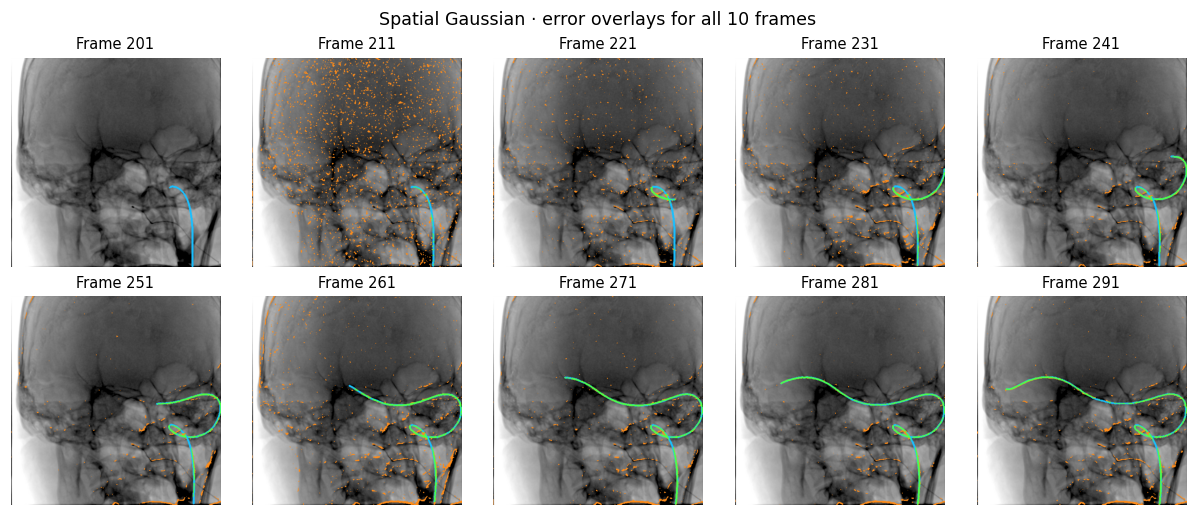

Spatial Gaussian | nine-frame means
SAD: 5910.333   MSE: 0.023   PSNR (dB): 17.090   SNR (dB): 17.046   Dice: 0.387   IoU: 0.258


In [9]:
spatial_frames = [ndimage.gaussian_filter(frame, sigma=GAUSSIAN_SIGMA, mode="nearest")
                  for frame in frames]
spatial_contrast = [stretch_contrast(frame, 0, 90) for frame in spatial_frames]
report_trial("Spatial Gaussian", threshold_masks(compute_normalized_differences(spatial_contrast)))

### 1.4 Spectral filtering
Apply a second-order Butterworth low-pass filter with a cutoff of 0.25 cycles per pixel after spatial smoothing. Measure the trade-off between suppressing high-frequency variation and preserving fine instrument edges.

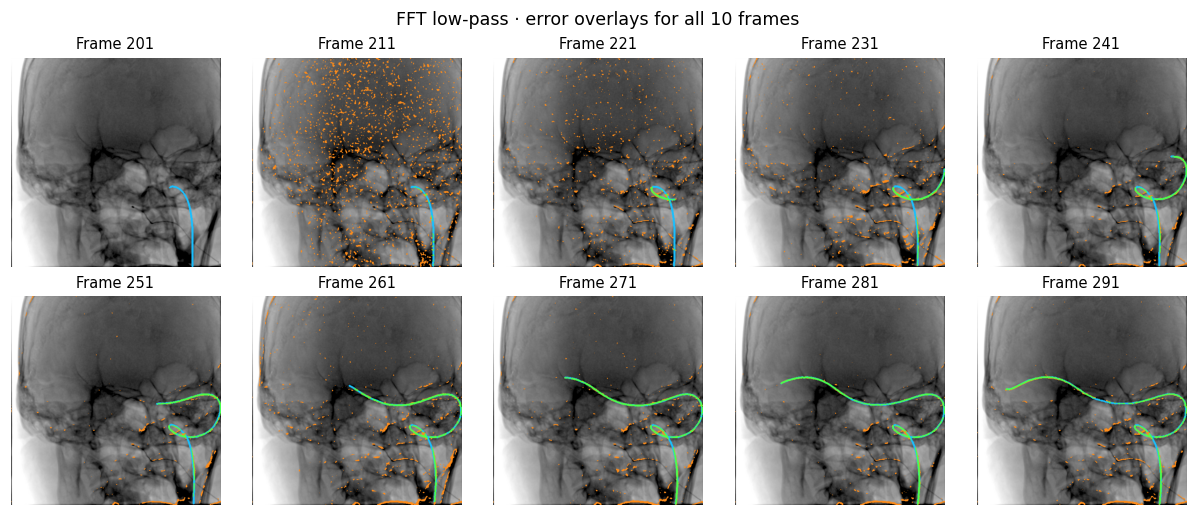

FFT low-pass | nine-frame means
SAD: 5834.556   MSE: 0.022   PSNR (dB): 17.220   SNR (dB): 17.176   Dice: 0.403   IoU: 0.273


In [10]:
def filter_in_frequency_domain(image, cutoff=0.25):
    vertical = np.fft.fftfreq(image.shape[0])[:, None]
    horizontal = np.fft.fftfreq(image.shape[1])[None, :]
    squared_frequency = vertical**2 + horizontal**2
    # Second-order Butterworth low-pass response in unshifted FFT coordinates.
    gain = 1 / (1 + (squared_frequency / cutoff**2)**2)
    return np.fft.ifft2(np.fft.fft2(image) * gain).real



filtered_frames = [stretch_contrast(filter_in_frequency_domain(frame), 0, 90)
                   for frame in spatial_frames]
report_trial("FFT low-pass", threshold_masks(compute_normalized_differences(filtered_frames)))

### 1.5 Morphology and segmentation
Dilate the grayscale difference with a radius-two disk to strengthen nearby responses. Compare a fixed threshold, Otsu’s histogram threshold and a two-component Gaussian mixture on this same motion map. The original solution opens the tool foreground for the two threshold methods and opens the background for EM, so the comparison covers the entire segmentation step.

In [11]:
def compute_otsu_threshold(motion_map):
    if motion_map.min() == motion_map.max():
        return motion_map.min()
    counts, edges = np.histogram(motion_map, bins=256)
    centers = (edges[:-1] + edges[1:]) / 2
    # Each histogram boundary is a candidate threshold; cumulative sums score all splits in one pass.
    lower_count = np.cumsum(counts)[:-1]
    upper_count = motion_map.size - lower_count
    lower_sum = np.cumsum(counts * centers)[:-1]
    # Both endpoint bins are occupied because the histogram spans the observed range.
    lower_mean = lower_sum / lower_count
    upper_mean = (np.dot(counts, centers) - lower_sum) / upper_count
    between_class_variance = lower_count.astype(float) * upper_count * (lower_mean - upper_mean) ** 2
    return centers[np.argmax(between_class_variance)]


def segment_with_gaussian_mixture(motion_map):
    if motion_map.min() == motion_map.max():
        return np.zeros_like(motion_map, dtype=bool)
    # Scikit-learn expects one row per pixel and one column for its motion intensity.
    intensities = motion_map.reshape(-1, 1)
    model = GaussianMixture(n_components=2, random_state=RANDOM_SEED).fit(intensities)
    # Component IDs are arbitrary. The brighter mean identifies the movement response.
    foreground_component = np.argmax(model.means_[:, 0])
    return model.predict(intensities).reshape(motion_map.shape) == foreground_component


def segment_motion_map(motion_map):
    fixed_mask = motion_map > FIXED_THRESHOLD
    otsu_mask = motion_map > compute_otsu_threshold(motion_map)
    mixture_mask = segment_with_gaussian_mixture(motion_map)
    # The source opens the foreground for thresholding and opens the background for EM.
    return {
        "Fixed threshold": ndimage.binary_opening(fixed_mask, structure=disk_footprint),
        "Otsu": ndimage.binary_opening(otsu_mask, structure=disk_footprint),
        "Gaussian mixture": ~ndimage.binary_opening(~mixture_mask, structure=disk_footprint,
                                                     border_value=1),
    }

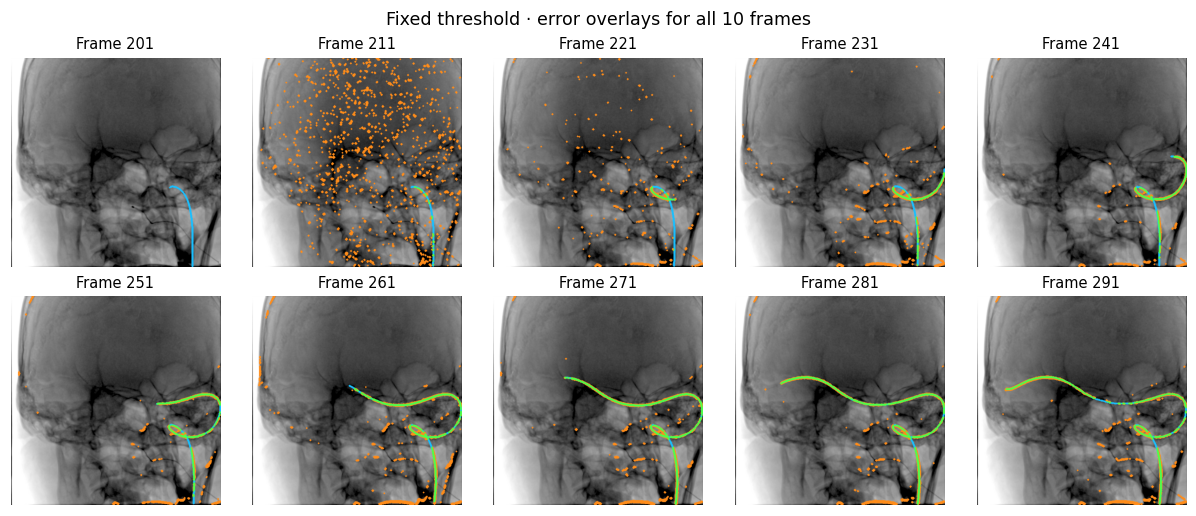

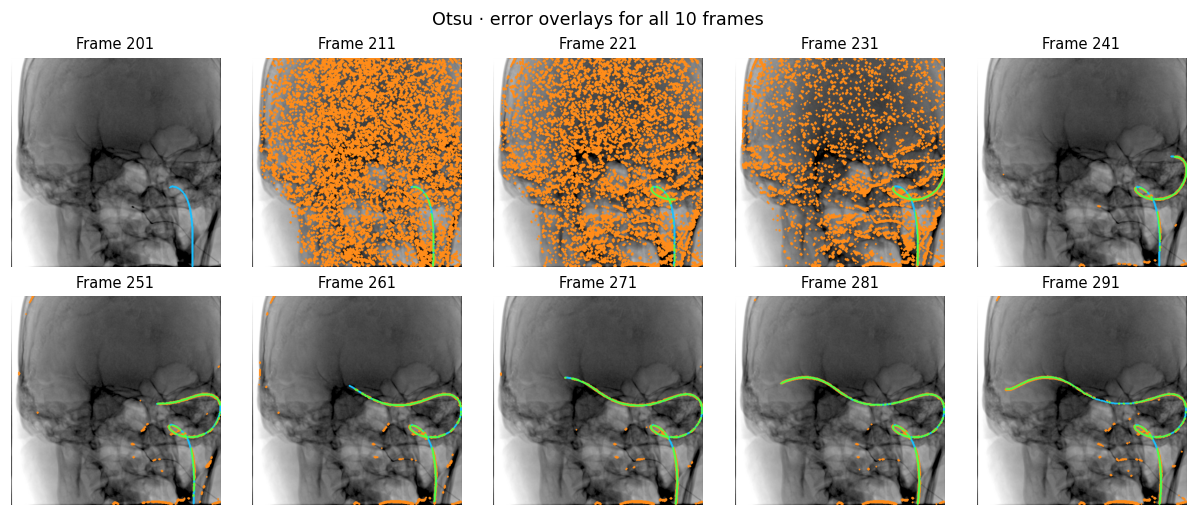

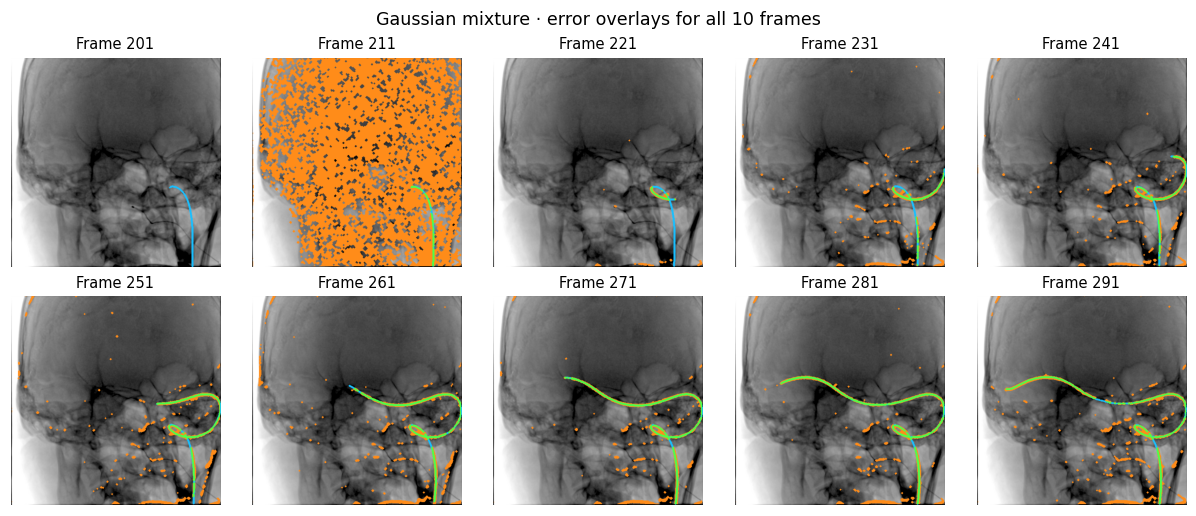

Fixed threshold | nine-frame means
SAD: 6831.556   MSE: 0.026   PSNR (dB): 16.575   SNR (dB): 16.531   Dice: 0.416   IoU: 0.280
Otsu | nine-frame means
SAD: 37336.667   MSE: 0.142   PSNR (dB): 13.945   SNR (dB): 13.901   Dice: 0.412   IoU: 0.295
Gaussian mixture | nine-frame means
SAD: 23975.778   MSE: 0.091   PSNR (dB): 15.300   SNR (dB): 15.256   Dice: 0.385   IoU: 0.249


In [12]:
def enhance_difference(prepared_reference, prepared_frame):
    difference = prepared_reference - prepared_frame
    local_maxima = ndimage.grey_dilation(difference, footprint=disk_footprint)
    return stretch_contrast(local_maxima, 10, 100)


candidate_masks = {}
for prepared_frame in filtered_frames:
    motion_map = enhance_difference(filtered_frames[0], prepared_frame)
    for method, tool_pixels in segment_motion_map(motion_map).items():
        candidate_masks.setdefault(method, []).append((~tool_pixels).astype(np.uint8))
for method, predictions in candidate_masks.items():
    report_trial(method, predictions)

**Observed changes.** The raw difference scored 20.35 dB PSNR but only 0.001 Dice: an almost empty prediction can match the large background while missing the tools. Contrast stretching raised Dice to 0.199. Spatial smoothing increased it to 0.387, the spectral filter to 0.403, and morphology to 0.416. Morphology improved overlap while reducing PSNR from 17.22 to 16.57 dB, illustrating the cost of expanding detections around thin structures.

Among the complete pipelines, fixed thresholding gives the highest mean PSNR and Dice on the later frames. Otsu has the best mean IoU. The retained rule uses PSNR and foreground Dice, treating both instrument overlap and whole-mask agreement as relevant.

### 1.6 Remove isolated black speckles
Label 8-connected instrument components. Keep a component if its horizontal or vertical span reaches the cutoff. This retains thin, long components without eroding their edges. Compare candidate cutoffs against the same annotations; a zero Dice on a subsequent frame signals loss of all overlap.

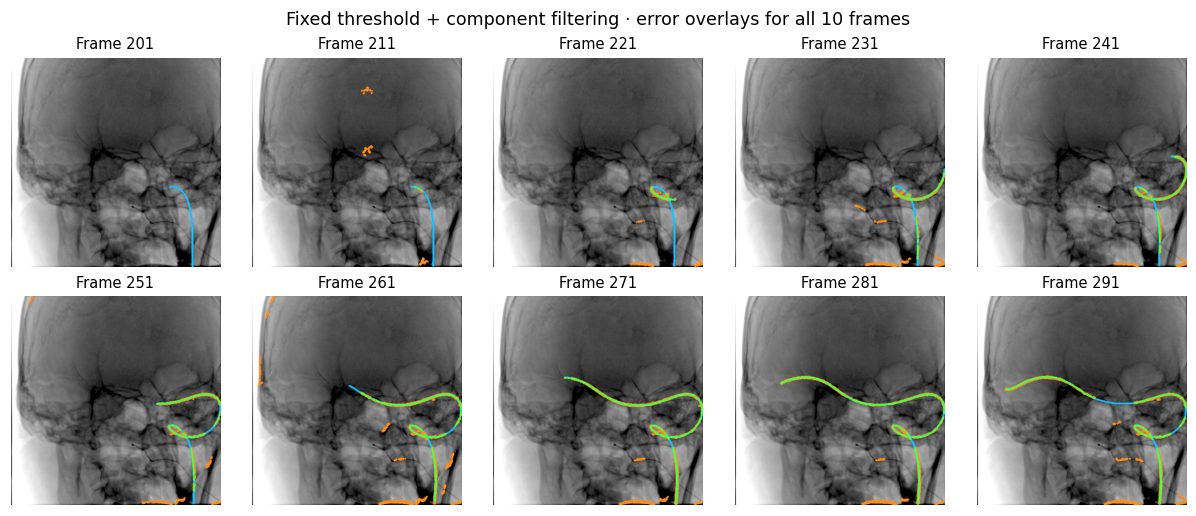

Span (px) | False-positive pixels | True-positive pixels | Mean Dice | Lowest Dice
        0 |                 57109 |                19414 |     0.416 |       0.033
       20 |                 24947 |                18549 |     0.483 |       0.066
       22 |                 22472 |                18549 |     0.501 |       0.083
       25 |                 20726 |                18163 |     0.496 |       0.000
       35 |                 17071 |                17911 |     0.521 |       0.000
       50 |                 15664 |                16511 |     0.504 |       0.000
Fixed threshold + component filtering | nine-frame means
SAD: 3079.111   MSE: 0.012   PSNR (dB): 19.522   SNR (dB): 19.478   Dice: 0.501   IoU: 0.352


In [13]:
def retain_extended_components(instrument_mask, minimum_span):
    labels, count = ndimage.label(instrument_mask, structure=np.ones((3, 3), dtype=bool))
    keep = np.zeros(count + 1, dtype=bool)
    for label, bounds in enumerate(ndimage.find_objects(labels), start=1):
        height, width = (axis.stop - axis.start for axis in bounds)
        keep[label] = max(height, width) >= minimum_span
    return keep[labels]


MINIMUM_SPAN = 22
baseline_masks = candidate_masks["Fixed threshold"]
print("Span (px) | False-positive pixels | True-positive pixels | Mean Dice | Lowest Dice")
for span in [0, 20, 22, 25, 35, 50]:
    filtered = [(~retain_extended_components(mask == 0, span)).astype(np.uint8)
                for mask in baseline_masks]
    detected = np.stack(filtered[1:]) == 0
    target = manual_masks[1:] == 0
    dice = [measure_mask_errors(mask, reference)["Dice"]
            for mask, reference in zip(filtered[1:], manual_masks[1:])]
    print(f"{span:9d} | {np.sum(detected & ~target):21d} | {np.sum(detected & target):20d} | "
          f"{np.mean(dice):9.3f} | {min(dice):11.3f}")
    if span == MINIMUM_SPAN:
        cleaned_masks = filtered

report_trial("Fixed threshold + component filtering", cleaned_masks)

The 22-pixel cutoff reduced speckle while improving Dice on every motion frame. Larger cutoffs discarded all overlapping pixels on frame 211. The cutoff is specific to these 512 × 512 images.

## 2. Classical pipeline (baseline) — code and description
The retained pipeline uses a fixed threshold of 0.10 followed by 8-connected component filtering at a minimum span of 22 pixels. The function below performs inference directly from the images, independently of the trial masks and annotations. Its parameters are shared across all ten frames. The first frame is preprocessed once and reused as the background model.

In [14]:
def prepare_fluoroscopy_frame(frame):
    # Smooth local noise and attenuate high spatial frequencies before enhancing contrast.
    smoothed = ndimage.gaussian_filter(frame, sigma=GAUSSIAN_SIGMA, mode="nearest")
    band_limited = filter_in_frequency_domain(smoothed, cutoff=0.25)
    return stretch_contrast(band_limited, 0, 90)


def detect_moving_instruments(current_frame, prepared_reference):
    prepared_current = prepare_fluoroscopy_frame(current_frame)
    # Background minus current highlights a newly arrived dark instrument.
    # Dilation links neighboring responses; the percentile stretch sets their common scale.
    motion_response = enhance_difference(prepared_reference, prepared_current)
    above_threshold = motion_response > FIXED_THRESHOLD
    # Opening removes small isolated responses. Save tools as 0 and background as 1.
    instrument_pixels = ndimage.binary_opening(above_threshold, structure=disk_footprint)
    return (~retain_extended_components(instrument_pixels, MINIMUM_SPAN)).astype(np.uint8)


prepared_reference = prepare_fluoroscopy_frame(frames[0])
classical_masks = np.stack([detect_moving_instruments(frame, prepared_reference) for frame in frames])
assert classical_masks.shape == frames.shape and np.isin(classical_masks, [0, 1]).all()
assert np.array_equal(classical_masks, cleaned_masks)
assert classical_masks[0].all()

### Supervised extension — appearance and continuous centerline tracking
The static background already contains the shaft. A line detector can recover it from the intensity profile. Sixteen oriented filters compare a dark central line with both flanks. A retrospective 80th-percentile image supplies a second source of evidence for the moving distal wire. Pixel coordinates encode the fixed projection and are one reason the method requires external testing.

In [15]:
from sklearn.ensemble import ExtraTreesClassifier

def dark_line_response(image):
    """Measure how much darker a narrow line is than the tissue on both sides."""
    response = np.zeros_like(image)
    for angle in np.linspace(0, np.pi, 16, endpoint=False):
        tangent = np.array([np.sin(angle), np.cos(angle)])
        offsets = np.rint(np.outer(np.arange(-5, 6), tangent)).astype(int)
        kernel = np.zeros((13, 13))
        np.add.at(kernel, tuple((offsets + 6).T), 1 / len(offsets))
        center = ndimage.convolve(image, kernel, mode="nearest")
        normal = np.rint(4 * np.array([tangent[1], -tangent[0]])).astype(int)
        left = ndimage.shift(center, normal, order=0, mode="nearest")
        right = ndimage.shift(center, -normal, order=0, mode="nearest")
        response = np.maximum(response, np.minimum(left, right) - center)
    return response


def extract_pixel_features(image, temporal_background):
    difference = temporal_background - image
    ridge = dark_line_response(image)
    row, column = np.indices(image.shape)
    channels = [row / image.shape[0], column / image.shape[1], image, difference, ridge,
                ndimage.maximum_filter(ridge, 5), ndimage.gaussian_filter(ridge, 2),
                ndimage.gaussian_filter(ridge, 6)]
    for scale in [1, 2.5, 6, 14]:
        channels.extend([image - ndimage.gaussian_filter(image, scale),
                         -ndimage.gaussian_laplace(image, scale) * scale**2,
                         ndimage.gaussian_filter(difference, scale)])
    derivatives = [(0, 1), (1, 0), (0, 2), (2, 0), (1, 1)]
    for scale in [1.5, 3]:
        channels.extend(ndimage.gaussian_filter(image, scale, order=order) for order in derivatives)
    changed_ridge = dark_line_response(-difference)
    channels.extend([changed_ridge, ndimage.maximum_filter(changed_ridge, 5),
                     ndimage.gaussian_filter(changed_ridge, 2), ndimage.gaussian_filter(changed_ridge, 6)])
    for scale in [1.5, 3]:
        channels.extend(ndimage.gaussian_filter(difference, scale, order=order) for order in derivatives)
    return np.stack(channels, axis=-1).astype(np.float32)


# Use the same retrospective image-only background for all folds. It includes future images.
images_8bit = np.rint(frames * 255)
temporal_background = np.percentile(images_8bit, 80, axis=0)
feature_maps = [extract_pixel_features(image, temporal_background) for image in images_8bit]

### Estimate held-out pixel scores
This is a retrospective, within-acquisition experiment. The new supervised method fits on other manually traced frames from the same acquisition. Each test pair and its immediate neighbors are excluded from fitting. The temporal background uses the raw images of the whole sequence. Model and path settings were explored on this sequence; the scores are development results, not independent patient-level validation.

In [16]:
def predict_held_out_pairs(feature_maps, training_targets):
    probabilities = [None] * len(feature_maps)
    fold_manifest = []
    for first in range(0, len(feature_maps), 2):
        held_out = list(range(first, min(first + 2, len(feature_maps))))
        # Exclude the test pair and its immediate neighboring frame on either side.
        train_indices = [j for j in range(len(feature_maps)) if not first - 1 <= j <= held_out[-1] + 1]
        samples, labels = [], []
        rng = np.random.default_rng(626)
        for index in train_indices:
            features = feature_maps[index]
            tool = training_targets[index]
            nearby_tissue = ndimage.maximum_filter(tool, 21) & ~tool
            dark_tissue = (training_ridges[index] > 2) & ~tool
            sampled = np.concatenate([np.flatnonzero(tool), rng.choice(np.flatnonzero(nearby_tissue), 3000),
                                      rng.choice(np.flatnonzero(dark_tissue), 6000),
                                      rng.choice(np.flatnonzero(~tool), 10000)])
            samples.append(features.reshape(-1, features.shape[-1])[sampled])
            labels.append(tool.ravel()[sampled])
        model = ExtraTreesClassifier(n_estimators=32, min_samples_leaf=3, random_state=626, n_jobs=4)
        model.fit(np.concatenate(samples), np.concatenate(labels))
        for index in held_out:
            features = feature_maps[index]
            pixels = features.reshape(-1, features.shape[-1])
            probabilities[index] = model.predict_proba(pixels)[:, 1].reshape(features.shape[:2])
        fold_manifest.append({"test_frames": [FRAME_NUMBERS[j] for j in held_out],
                              "training_frames": [FRAME_NUMBERS[j] for j in train_indices]})
    return probabilities, fold_manifest


training_ridges = [dark_line_response(image) for image in images_8bit]
tool_scores, validation_folds = predict_held_out_pairs(feature_maps, reference_masks)

### Decode one smooth path per frame
The geometry assumes a single, continuous instrument assembly entering at the lower edge in this view. The start column is chosen from the score map. A beam search advances three pixels at a time, balancing local evidence against curvature. A two-pixel disk converts the centerline to the target mask thickness. This geometry suppresses disconnected detections by construction. It can still follow the wrong edge, miss the tip or be unsuitable for a different entry geometry.

In [17]:
def trace_instrument(score_map):
    """Trace one smoothly turning instrument entering through the lower image border."""
    height, width = score_map.shape
    evidence = ndimage.gaussian_filter(score_map, 1.0)
    start_column = np.argmax(evidence[-12:].mean(axis=0))
    start = np.array([height - 2., float(start_column)])
    angles = np.arange(36) * 2 * np.pi / 36
    step_vectors = 3 * np.column_stack([np.sin(angles), np.cos(angles)])
    # Each hypothesis records accumulated evidence, position, heading and point history.
    hypotheses = [(0., start, 27, [start])]
    best_score, best_path = 0., []
    for _ in range(320):
        successors = {}
        for cumulative, position, heading, history in hypotheses:
            candidates = position + step_vectors
            for turn in [-2, -1, 0, 1, 2]:
                next_heading = (heading + turn) % len(angles)
                candidate = candidates[next_heading]
                row, column = np.rint(candidate).astype(int)
                if not (0 <= row < height and 0 <= column < width):
                    continue
                # Allow crossing the loop, but avoid scoring the same segment repeatedly.
                if len(history) > 10:
                    earlier = np.asarray(history[:-7])
                    overlaps = np.flatnonzero(np.sum((earlier - candidate)**2, axis=1) < 2.5**2)
                    if any(abs(np.dot(earlier[k] - earlier[k-1], step_vectors[next_heading])) > 7
                           for k in overlaps if k > 0):
                        continue
                next_score = cumulative + evidence[row, column] - 0.46 - 0.023 * abs(turn) - 0.002 * turn**2
                if next_score < best_score - 4:
                    continue
                state = (row // 2, column // 2, next_heading // 2)
                if state not in successors or successors[state][0] < next_score:
                    successors[state] = (next_score, candidate, next_heading, history + [candidate])
        if not successors:
            break
        hypotheses = sorted(successors.values(), key=lambda item: -item[0])[:12]
        if hypotheses[0][0] > best_score:
            best_score, best_path = hypotheses[0][0], hypotheses[0][3]

    centerline = np.zeros_like(score_map, dtype=bool)
    for start_point, end_point in zip(best_path, best_path[1:]):
        pixels = np.rint(np.linspace(start_point, end_point, 7)).astype(int)
        centerline[pixels[:, 0], pixels[:, 1]] = True
    return ndimage.binary_dilation(centerline, structure=disk_footprint)


output_masks = np.stack([(~trace_instrument(scores)).astype(np.uint8) for scores in tool_scores])
for number, encoded_mask in zip(FRAME_NUMBERS, output_masks):
    _, components = ndimage.label(encoded_mask == 0, structure=np.ones((3, 3)))
    print(f"Frame {number}: {components} predicted instrument component(s)")

Frame 201: 1 predicted instrument component(s)
Frame 211: 1 predicted instrument component(s)
Frame 221: 1 predicted instrument component(s)
Frame 231: 1 predicted instrument component(s)
Frame 241: 1 predicted instrument component(s)
Frame 251: 1 predicted instrument component(s)
Frame 261: 1 predicted instrument component(s)
Frame 271: 1 predicted instrument component(s)
Frame 281: 1 predicted instrument component(s)
Frame 291: 1 predicted instrument component(s)


### Paired comparison with the prior automatic baseline
Each row compares both methods on the same frame and full expanded manual mask. The classical reference-frame prediction is empty by design.

In [18]:
comparison_rows = []
for number, baseline, prediction, manual in zip(FRAME_NUMBERS, classical_masks, output_masks, manual_masks):
    original = measure_mask_errors(baseline, manual)
    result = measure_mask_errors(prediction, manual)
    comparison_rows.append({"frame": number, "baseline_dice": original["Dice"], "new_dice": result["Dice"],
                            "baseline_fp": int(np.sum((baseline == 0) & (manual == 1))),
                            "new_fp": int(np.sum((prediction == 0) & (manual == 1))),
                            "baseline_fn": int(np.sum((baseline == 1) & (manual == 0))),
                            "new_fn": int(np.sum((prediction == 1) & (manual == 0)))})
print("Frame   Baseline Dice   New Dice   False positives   Missed pixels")
for row in comparison_rows:
    print(f"{row['frame']:5} {row['baseline_dice']:15.3f} {row['new_dice']:10.3f}"
          f"{row['new_fp']:18} {row['new_fn']:15}")
with open("frame_comparison.csv", "w", newline="") as output:
    writer = csv.DictWriter(output, fieldnames=comparison_rows[0])
    writer.writeheader()
    writer.writerows(comparison_rows)

Frame   Baseline Dice   New Dice   False positives   Missed pixels
  201           0.000      0.932                86              63
  211           0.083      0.932                94              55
  221           0.287      0.818               444             118
  231           0.467      0.889               221             202
  241           0.596      0.883               271             222
  251           0.583      0.847               435             391
  261           0.544      0.884               384             380
  271           0.667      0.878               480             409
  281           0.691      0.908               413             320
  291           0.588      0.849               811             414


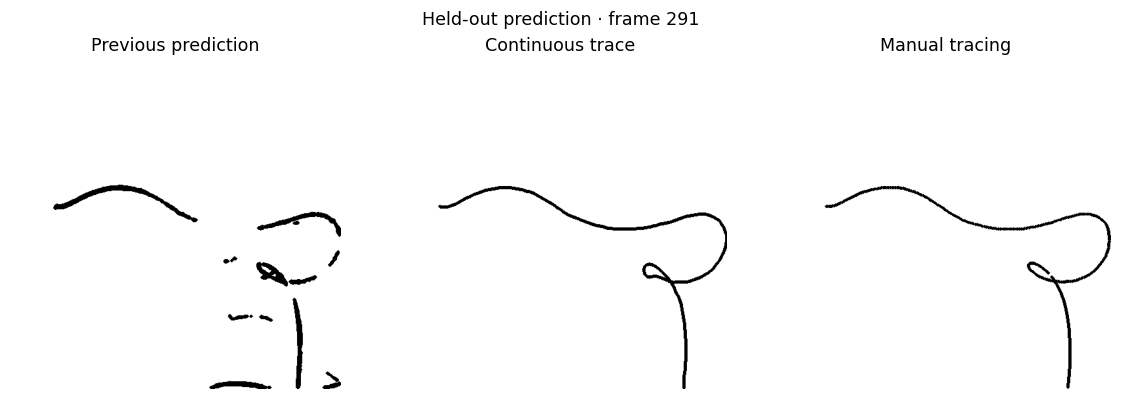

In [19]:
comparison_index = -1
figure, axes = plt.subplots(1, 3, figsize=(11, 3.7), constrained_layout=True)
for axis, view, title in zip(axes, [classical_masks[comparison_index], output_masks[comparison_index],
                                   manual_masks[comparison_index]], ["Previous prediction", "Continuous trace", "Manual tracing"]):
    axis.imshow(view, cmap="gray", vmin=0, vmax=1)
    axis.set_title(title)
    axis.set_axis_off()
figure.suptitle(f"Held-out prediction · frame {FRAME_NUMBERS[comparison_index]}")
plt.show()

### Results — qualitative comparison
Each row contains one prediction, the paired manual mask and the green-channel overlay on the contrast-enhanced fluoroscopy image. The first row verifies the zero-motion reference case.

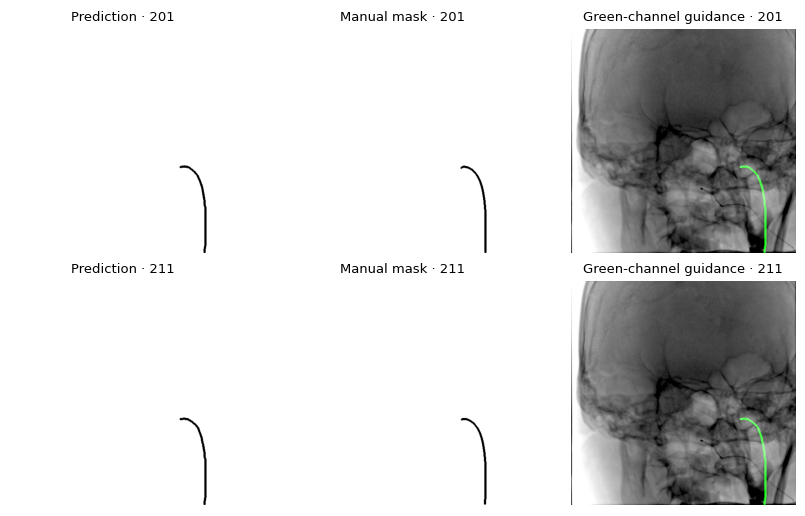

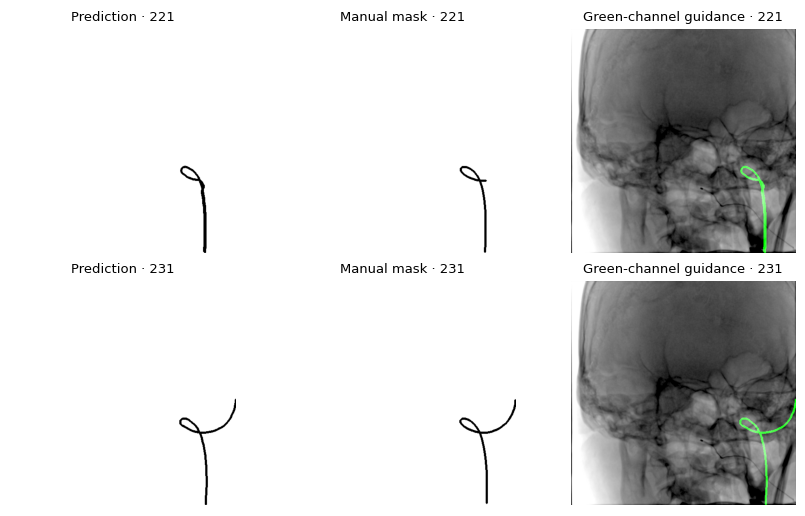

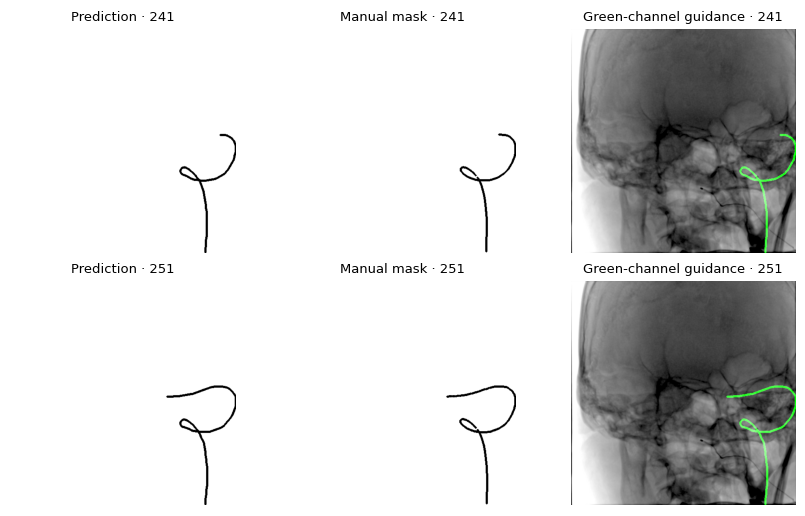

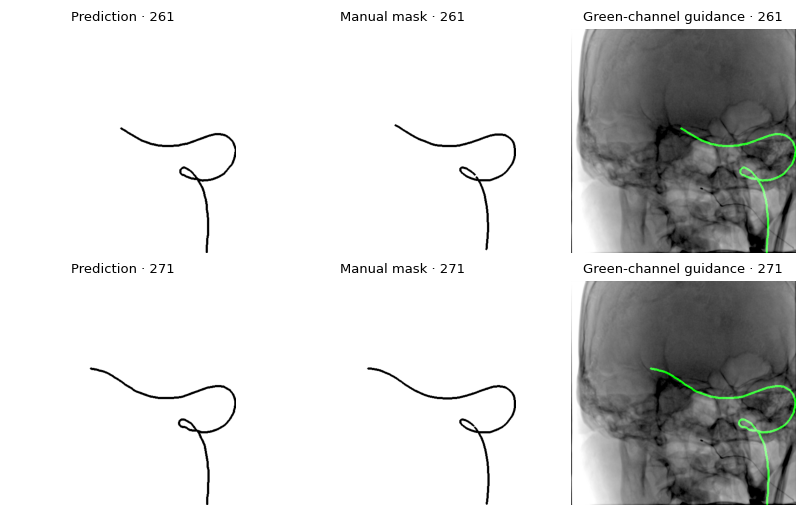

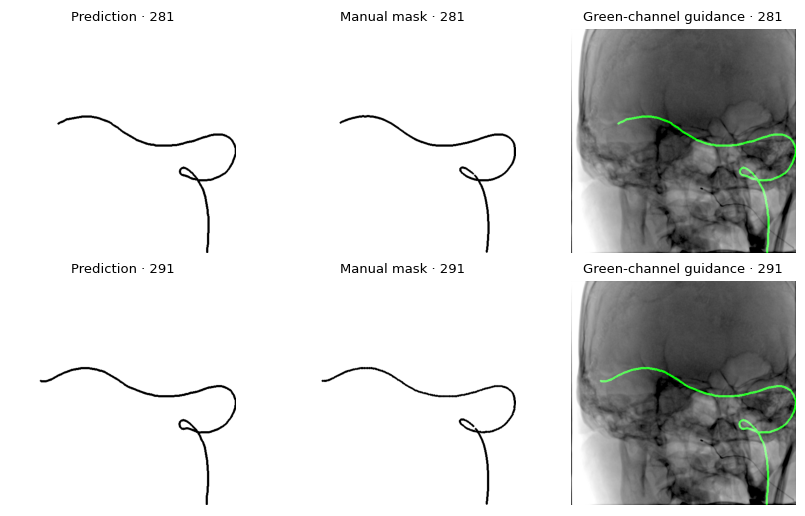

In [20]:
def show_frame_comparisons(first_index, last_index):
    count = last_index - first_index
    figure, axes = plt.subplots(count, 3, figsize=(8, 2.4 * count), squeeze=False,
                                constrained_layout=True)
    for row, index in enumerate(range(first_index, last_index)):
        enhanced = display_frames[index]
        guidance = np.repeat(enhanced[:, :, None], 3, axis=2)
        guidance[:, :, 1][output_masks[index] == 0] = 1
        for axis, view, title in zip(axes[row], [output_masks[index], manual_masks[index], guidance],
                                     ["Prediction", "Manual mask", "Green-channel guidance"]):
            axis.imshow(view, cmap="gray", vmin=0, vmax=1)
            axis.set_title(f"{title} · {FRAME_NUMBERS[index]}", fontsize=9)
            axis.set_axis_off()
    plt.show()


for first_index in range(0, len(frames), 2):
    show_frame_comparisons(first_index, min(first_index + 2, len(frames)))

### Results — per-frame errors, temporal evolution and sequence statistics
All metrics use the full expanded union of the manual tracings. The horizontal axis gives elapsed acquisition frames from the reference. A frame rate was not supplied.

In [21]:
frame_results = [measure_mask_errors(mask, target)
                 for mask, target in zip(output_masks, manual_masks, strict=True)]
metric_names = list(frame_results[0])
print("Frame" + "".join(f"{name:>12}" for name in metric_names))
for number, result in zip(FRAME_NUMBERS, frame_results, strict=True):
    print(f"{number:5}" + "".join(f"{result[name]:12.4f}" for name in metric_names))

Frame         SAD         MAE         SSE         MSE   PSNR (dB)    SNR (dB)        Dice         IoU
  201    149.0000      0.0006    149.0000      0.0006     32.4535     32.4356      0.9319      0.8725
  211    149.0000      0.0006    149.0000      0.0006     32.4535     32.4358      0.9317      0.8721
  221    562.0000      0.0021    562.0000      0.0021     26.6880     26.6651      0.8180      0.6921
  231    423.0000      0.0016    423.0000      0.0016     27.9220     27.8905      0.8889      0.8001
  241    493.0000      0.0019    493.0000      0.0019     27.2569     27.2223      0.8831      0.7907
  251    826.0000      0.0032    826.0000      0.0032     25.0156     24.9710      0.8472      0.7349
  261    764.0000      0.0029    764.0000      0.0029     25.3545     25.2998      0.8835      0.7913
  271    889.0000      0.0034    889.0000      0.0034     24.6964     24.6360      0.8784      0.7831
  281    733.0000      0.0028    733.0000      0.0028     25.5344     25.4687     

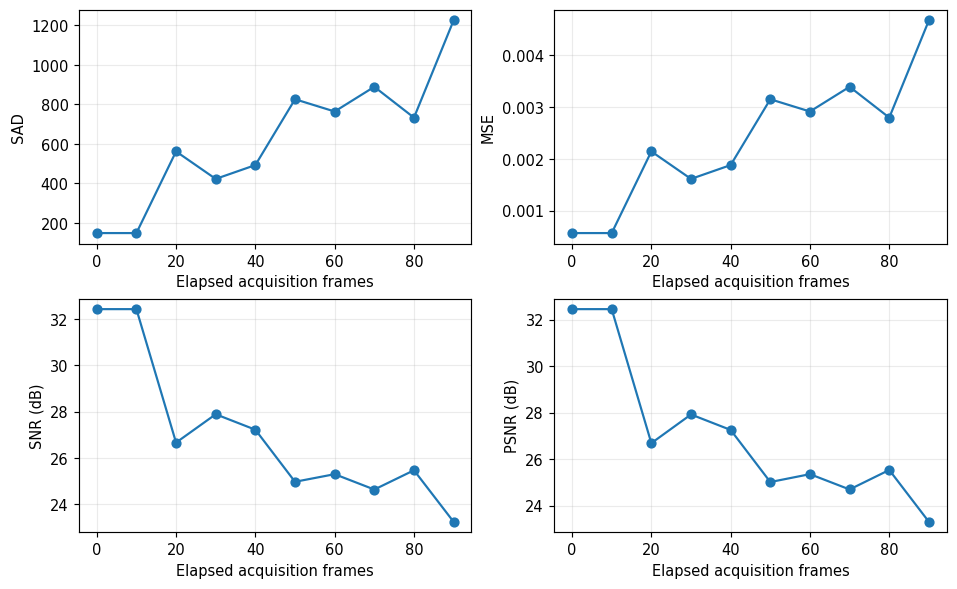

In [22]:
elapsed_frames = np.array(FRAME_NUMBERS) - FRAME_NUMBERS[0]
figure, axes = plt.subplots(2, 2, figsize=(9, 5.5), constrained_layout=True)
for axis, metric in zip(axes.flat, ["SAD", "MSE", "SNR (dB)", "PSNR (dB)"]):
    axis.plot(elapsed_frames, [result[metric] for result in frame_results], marker="o")
    axis.set(xlabel="Elapsed acquisition frames", ylabel=metric)
    axis.grid(alpha=0.25)
plt.show()

In [23]:
print(f"{'Metric':<12}{'Mean':>14}{'Population SD':>16}")
for metric in metric_names:
    values = [result[metric] for result in frame_results]
    print(f"{metric:<12}{np.mean(values):14.4f}{np.std(values, ddof=0):16.4f}")

Metric                Mean   Population SD
SAD               621.3000        318.7937
MAE                 0.0024          0.0012
SSE               621.3000        318.7937
MSE                 0.0024          0.0012
PSNR (dB)          27.0679          2.9700
SNR (dB)           27.0264          2.9853
Dice                0.8819          0.0348
IoU                 0.7905          0.0555


### Export the ten binary masks
Write a single-channel PNG for each frame and read it back to verify the literal 0/1 pixel values. Standard image viewers display both values as nearly black; the report scales these values for viewing.

In [24]:
def write_binary_png(path, mask):
    # Store one 8-bit grayscale sample per pixel; no palette or intensity rescaling.
    height, width = mask.shape
    def chunk(kind, payload):
        checksum = zlib.crc32(kind + payload)
        return struct.pack(">I", len(payload)) + kind + payload + struct.pack(">I", checksum)

    header = struct.pack(">IIBBBBB", width, height, 8, 0, 0, 0, 0)
    rows = b"".join(bytes([0]) + row.tobytes() for row in mask)
    path.write_bytes(bytes.fromhex("89504e470d0a1a0a") + chunk(b"IHDR", header)
                     + chunk(b"IDAT", zlib.compress(rows)) + chunk(b"IEND", b""))


mask_directory = Path("output_masks")
mask_directory.mkdir(exist_ok=True)
for number, mask in zip(FRAME_NUMBERS, output_masks, strict=True):
    path = mask_directory / f"mask_{number}.png"
    write_binary_png(path, mask)
    assert np.array_equal(np.rint(255 * plt.imread(path)).astype(np.uint8), mask)
print(f"Verified {len(output_masks)} grayscale PNG masks.")

Verified 10 grayscale PNG masks.


**Conclusion.** The appearance model and path constraint recover a continuous shaft and distal wire on this acquisition. Compare per-frame Dice and false-positive and missed-pixel counts above. A connected prediction can still be offset from the manual tracing.

## Experience gained
- **Designed a controlled image-processing experiment.** Kept the frames, annotations and threshold fixed while adding contrast stretching, spatial smoothing, frequency filtering and morphology. This isolated the effect of each change on the instrument mask.
- **Evaluated thin structures against manual tracings.** Combined the guidewire and microcatheter annotations, made the two-pixel tracing tolerance explicit, and checked both foreground overlap and whole-image error.
- **Investigated failure cases.** The classical baseline produced scattered detections on frame 211. The paired comparison measures how the continuous trace changes this failure. On frame 281, much more of the traced instrument is recovered. These differences would be hidden by a single sequence average.

**Scope of the evidence.** The methods were compared and selected on the same nine subsequent frames. An independent acquisition would be needed to evaluate how well the selected threshold transfers.

## Retrospective reader handoff
Open the chronological review sheet to inspect each source image alongside its manual tracing, prediction and error overlay. First inspect the original image and record whether the instrument is visible. Then check for gaps, spurious detections and disagreement with the manual tracing. The reference frame is included for context. A blank clinical assessment means that a reader has yet to review the frame.

Enter observations below each frame in the interactive review sheet. Drafts use local browser storage and can be exported to CSV. A blank CSV template is also provided. The run manifest records the source, algorithm settings and per-mask checksums. The manual tracing is the reference standard for this exercise; its reader provenance and inter-reader variability are unknown. Reporting terminology follows the distinction between reference standards and external testing in [CLAIM 2024](https://doi.org/10.1148/ryai.240300).

In [25]:
from importlib.metadata import version

review_directory = Path("review")
review_directory.mkdir(exist_ok=True)
review_rows = []
html_sections = []
mask_digests = {}
for index, number in enumerate(FRAME_NUMBERS):
    target = manual_masks[index] == 0
    detected = output_masks[index] == 0
    enhanced = display_frames[index]
    errors = np.repeat(enhanced[:, :, None], 3, axis=2)
    errors[target & detected] = [0.3, 1, 0.3]
    errors[~target & detected] = [1, 0.55, 0.1]
    errors[target & ~detected] = [0.1, 0.75, 1]
    role = "Background reference" if index == 0 else "Subsequent frame"
    figure, axes = plt.subplots(1, 5, figsize=(15, 3), constrained_layout=True)
    for axis, view, title in zip(axes, [frames[index], enhanced, manual_masks[index], output_masks[index], errors],
                                 ["Original", "Enhanced", "Manual tracing", "Predicted mask", "Error overlay"]):
        axis.imshow(view, cmap="gray", vmin=0, vmax=1)
        axis.set_title(title)
        axis.set_axis_off()
    image_name = f"frame_{number}_review.png"
    figure.savefig(review_directory / image_name, dpi=120, bbox_inches="tight")
    plt.close(figure)
    missed = np.count_nonzero(target & ~detected)
    spurious = np.count_nonzero(detected & ~target)
    score = frame_results[index]["Dice"]
    review_rows.append({"frame": number, "role": role, "dice": round(score, 4),
                        "missed_pixels": missed, "false_positive_pixels": spurious,
                        "review_status": "Pending human review", "visibility": "",
                        "reviewer_findings": "", "reviewer": "", "review_date": ""})
    html_sections.append(f'<section id="f{number}"><h2>Frame {number} · {role}</h2>'
                         f'<img src="{image_name}" alt="Original, enhanced, manual tracing, prediction and error overlay">'
                         f'<p>Dice {score:.3f} · Missed {missed:,} pixels · False positives {spurious:,} pixels</p></section>')
    mask_path = mask_directory / f"mask_{number}.png"
    mask_digests[mask_path.name] = hashlib.sha256(mask_path.read_bytes()).hexdigest()

with (review_directory / "reader_template.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=review_rows[0].keys())
    writer.writeheader()
    writer.writerows(review_rows)
manifest = {"prediction_method": "ExtraTrees + continuous path", "validation_folds": validation_folds, "temporal_background_percentile": 80, "tree_count": 32, "model_seed": 626, "beam_width": 12, "path_score_offset": 0.46, "entry_assumption": "lower image edge", "classical_baseline_min_span": MINIMUM_SPAN, "minimum_component_span_px": MINIMUM_SPAN, "component_connectivity": 8, "display_window": display_window.tolist(), "display_gamma": 0.60, "display_local_contrast_gain": 0.7, "display_local_sigma_px": 10, "task": "Offline retrospective technical evaluation", "input_sha256": archive_digest,
            "frame_numbers": FRAME_NUMBERS, "reference_frame": FRAME_NUMBERS[0],
            "shape": list(frames.shape), "threshold": FIXED_THRESHOLD, "gaussian_sigma_px": GAUSSIAN_SIGMA,
            "butterworth_cutoff_cycles_per_pixel": 0.25, "morphology_radius_px": RADIUS_PIXELS,
            "intensity_percentiles": [0, 90], "difference_percentiles": [10, 100],
            "tool_label": 0, "background_label": 1, "mask_sha256": mask_digests,
            "software": {package: version(package) for package in ["numpy","scipy","matplotlib","scikit-learn"]}}
(review_directory / "run_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
navigation = " · ".join(f'<a href="#f{n}">{n}</a>' for n in FRAME_NUMBERS)
page = ('<!doctype html><html lang="en"><meta charset="utf-8"><meta name="viewport" content="width=device-width">'
        '<title>Fluoroscopy | Retrospective frame review</title>'
        '<style>body{max-width:1100px;margin:32px auto;padding:0 16px;font:16px/1.5 system-ui;color:#19354b}'
        'section{border-top:1px solid #ccd5da;margin-top:28px}img{width:100%}a{color:#146676}'
        '@media print{section{break-inside:avoid}}</style><h1>Retrospective frame review</h1><p>Project by Denos Kume and Oluwole Shokunbi</p>'
        '<p>Teaching acquisition · Offline research · Reader worksheet</p>'
        '<p>Compare the original and enhanced images with the tracing and prediction. Green marks agreement on tool pixels, '
        'orange marks false positives and blue marks missed tools. Record observations below each frame and export the worksheet to keep a portable copy.</p>'
        '<nav>Frames: ' + navigation + '</nav>' + ''.join(html_sections) + '</html>')
# Keep the reader offline and bind its draft to this input and these output masks.
run_key = hashlib.sha256(json.dumps(manifest, sort_keys=True).encode()).hexdigest()
case_data = json.dumps({"rows": review_rows, "run": run_key}, default=int)
page = page.replace("<nav>", '<style>fieldset{display:grid;grid-template-columns:repeat(auto-fit,minmax(180px,1fr));gap:12px;border:1px solid #b3c8c6;padding:14px}label{display:grid;gap:4px}input,select,textarea,button{font:inherit;padding:6px}textarea{min-height:55px}.toolbar{position:sticky;top:0;display:flex;flex-wrap:wrap;gap:12px;align-items:center;background:white;border-bottom:1px solid #abc;padding:8px 0;z-index:1}button{background:#164f51;color:white;border:0;border-radius:4px;cursor:pointer}section{scroll-margin-top:85px}@media print{.toolbar{display:none}}</style><div class="toolbar"><strong id="progress"></strong><button type="button" id="export">Export worksheet (CSV)</button><span role="status" id="save-state">Changes are saved in this browser when storage is available.</span></div><nav>')
page = page.replace("</html>", '<script type="application/json" id="case-data">' + case_data + '</script>' + '<script>const {rows, run} = JSON.parse(document.querySelector(\'#case-data\').textContent);\nconst draftKey = \'fluoroscopy-review:\' + run;\nconst editable = [\'review_status\',\'visibility\',\'reviewer_findings\',\'reviewer\',\'review_date\'];\nconst statusLine = document.querySelector(\'#save-state\');\ntry {\n  const saved = JSON.parse(localStorage.getItem(draftKey) || \'{}\');\n  for (const row of rows) {\n    for (const field of editable) {\n      const value = saved[row.frame]?.[field];\n      if (typeof value === \'string\') row[field] = value;\n    }\n  }\n} catch { statusLine.textContent = \'Browser storage unavailable. Export your work to keep a copy.\'; }\n\nfunction updateCount() {\n  const reviewed = rows.filter(row => row.review_status === \'Reviewed\').length;\n  document.querySelector(\'#progress\').textContent = reviewed + \' of \' + rows.length + \' frames reviewed\';\n}\nfunction saveDraft() {\n  try {\n    localStorage.setItem(draftKey, JSON.stringify(Object.fromEntries(rows.map(row => [row.frame, row]))));\n    statusLine.textContent = \'Draft saved in this browser.\';\n  } catch { statusLine.textContent = \'Draft could not be saved. Export your work before closing.\'; }\n  updateCount();\n}\nconst fields = [\n  [\'reviewer\',\'Reviewer\',\'text\'], [\'review_date\',\'Review date\',\'date\'],\n  [\'visibility\',\'Instrument visibility\',[\'\',\'Visible\',\'Partly visible\',\'Not visible\',\'Unable to assess\']],\n  [\'reviewer_findings\',\'Observations\',\'textarea\'],\n  [\'review_status\',\'Review status\',[\'Pending human review\',\'In progress\',\'Reviewed\']]\n];\nfor (const row of rows) {\n  const form = document.createElement(\'fieldset\');\n  const legend = document.createElement(\'legend\');\n  legend.textContent = \'Reader assessment · frame \' + row.frame;\n  form.append(legend);\n  for (const [key, title, type] of fields) {\n    const label = document.createElement(\'label\');\n    label.textContent = title;\n    const input = document.createElement(Array.isArray(type) ? \'select\' : type === \'textarea\' ? \'textarea\' : \'input\');\n    if (Array.isArray(type)) {\n      for (const option of type) input.add(new Option(option || \'Choose visibility\',option));\n    } else if (input.tagName === \'INPUT\') input.type = type;\n    input.id = key + \'-\' + row.frame;\n    input.value = row[key];\n    input.addEventListener(\'input\', () => {\n      if (key === \'review_status\' && input.value === \'Reviewed\' &&\n          !(row.reviewer.trim() && row.review_date && row.visibility)) {\n        input.value = row.review_status;\n        statusLine.textContent = \'Enter the reviewer, date and visibility before marking this frame reviewed.\';\n        return;\n      }\n      row[key] = input.value;\n      if (row.review_status === \'Reviewed\' && !(row.reviewer.trim() && row.review_date && row.visibility)) {\n        row.review_status = \'In progress\';\n        document.getElementById(\'review_status-\' + row.frame).value = row.review_status;\n      }\n      saveDraft();\n    });\n    label.append(input);\n    form.append(label);\n  }\n  document.querySelector(\'#f\' + row.frame).append(form);\n}\nupdateCount();\nfunction csvValue(value) {\n  let text = String(value ?? \'\');\n  if (/^[\\s]*[=+@-]/.test(text)) text = "\'" + text;\n  return \'"\' + text.replaceAll(\'"\', \'""\') + \'"\';\n}\ndocument.querySelector(\'#export\').addEventListener(\'click\', () => {\n  const columns = Object.keys(rows[0]);\n  const records = [columns, ...rows.map(row => columns.map(key => row[key]))];\n  const csv = records.map(record => record.map(csvValue).join(\',\')).join(\'\\r\\n\');\n  const url = URL.createObjectURL(new Blob([\'\\uFEFF\' + csv], {type: \'text/csv;charset=utf-8\'}));\n  const link = document.createElement(\'a\');\n  link.href = url; link.download = \'fluoroscopy-frame-review.csv\'; link.click();\n  setTimeout(() => URL.revokeObjectURL(url), 5000);\n});\n</script></html>')
(review_directory / "index.html").write_text(page, encoding="utf-8")
print(f"Prepared {len(review_rows)} review entries and verified mask hashes for the run manifest.")

Prepared 10 review entries and verified mask hashes for the run manifest.
